# PING 수익화 전환 흐름 분석

익명 투표 SNS 앱 PING의 회원·결제 DB와 앱 행동 로그(Hackle)로 결제까지 이어지는 흐름을 분석한 노트북입니다. 팀 프로젝트에서 제가 맡은 데이터 전처리와 결제 경로 분석 부분을 정리했습니다.

- 원본 데이터는 비공개라 포함하지 않았습니다. 실행하려면 `votes/`, `hackle/` 폴더에 데이터가 필요합니다.
- 유저 단위 식별 정보(device_id, session_id 등)가 보이는 출력은 지웠습니다.

## 0. 데이터 불러오기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

DATA_DIR1 = "votes/"    # 서비스 DB
DATA_DIR2 = "hackle/"   # 앱 행동 로그

user            = pd.read_csv(DATA_DIR1 + "accounts_user.csv")
paymenthistory  = pd.read_csv(DATA_DIR1 + "accounts_paymenthistory.csv")
pointhistory    = pd.read_csv(DATA_DIR1 + "accounts_pointhistory.csv")
blockrecord     = pd.read_csv(DATA_DIR1 + "accounts_blockrecord.csv")
timelinereport  = pd.read_csv(DATA_DIR1 + "accounts_timelinereport.csv")
polls_qreport   = pd.read_csv(DATA_DIR1 + "polls_questionreport.csv")

hackle_prop     = pd.read_csv(DATA_DIR2 + "hackle_properties.csv")
hackle_events   = pd.read_csv(DATA_DIR2 + "hackle_events.csv")

## 1. 전처리

- 서비스 DB의 시간은 UTC로 저장돼 있어 모두 KST(+9시간)로 변환했습니다. Hackle 로그는 KST로 저장돼 있어 그대로 사용했습니다.
- 신고·차단 기록은 같은 유저·대상·사유로 1분 안에 반복된 기록을 1건으로 정리했습니다.

### 1-1. 회원 (운영 계정 제거, 리스트 컬럼 파싱)

In [2]:
#accounts_user

user = user.copy()

# 운영계정 제거
user = user[
    (user['is_superuser'] == 0) & (user['is_staff'] == 0)
].copy()

# pending_chat 음수 → 0
user['pending_chat'] = user['pending_chat'].clip(lower=0)

# created_at KST 변환
user['created_at'] = pd.to_datetime(user['created_at'], errors='coerce') \
                           + pd.Timedelta(hours=9)

# 리스트 파싱 필요
import ast

def parse_list_safe(x):
    if pd.isna(x):
        return []

    if isinstance(x, list):
        return x

    try:
        parsed = ast.literal_eval(str(x))
        return parsed if isinstance(parsed, list) else []
    except:
        return []

# accounts_user 리스트 컬럼 파싱
user["friend_id_list_parsed"] = user["friend_id_list"].apply(parse_list_safe)
user["block_user_id_list_parsed"] = user["block_user_id_list"].apply(parse_list_safe)
user["hide_user_id_list_parsed"] = user["hide_user_id_list"].apply(parse_list_safe)

# 개수 파생
user["friend_count"] = user["friend_id_list_parsed"].apply(len)
user["block_count"] = user["block_user_id_list_parsed"].apply(len)
user["hide_count"] = user["hide_user_id_list_parsed"].apply(len)

### 1-2. 결제 내역 (KST 변환, 하트 수량 파생)

In [3]:
#accounts_paymenthistory

HEART_MAP = {
    'heart.200' :  200,
    'heart.777' :  777,
    'heart.1000': 1000,
    'heart.4000': 4000,
}

paymenthistory_clean = paymenthistory.copy()

# heart_amount 파생변수 생성
paymenthistory_clean['heart_amount'] = paymenthistory_clean['productId'].map(HEART_MAP)

# created_at KST 변환
paymenthistory_clean['created_at'] = pd.to_datetime(
    paymenthistory_clean['created_at'], errors='coerce'
) + pd.Timedelta(hours=9)

### 1-3. 차단 기록 (1분 내 반복 기록 정리)

In [4]:
#accounts_blockrecord

# 1. 복사 및 KST 변환
df_abr = blockrecord.copy()

# 문자열 → datetime
df_abr['created_at'] = pd.to_datetime(df_abr['created_at'])

# UTC → KST
df_abr['created_at'] = df_abr['created_at'] + pd.Timedelta(hours=9)

# 시간 흐름대로 정렬
df_abr = df_abr.sort_values(by=['user_id', 'reason', 'block_user_id', 'created_at'])

# 2. 유저, 차단 대상, 사유가 모두 일치하는 그룹 내에서 시간 차이(초) 계산
df_abr['time_diff_sec'] = df_abr.groupby(['user_id', 'block_user_id', 'reason'])['created_at'].diff().dt.total_seconds()

# 3. 삭제 대상 정의: 시간 차이가 60초 이내인 데이터 행들의 인덱스 추출
drop_condition = (df_abr['time_diff_sec'].notnull()) & (df_abr['time_diff_sec'] <= 60)
delete_indices = df_abr[drop_condition].index

print(f"정제 전 데이터 건수 : {len(df_abr):,}건")
print(f"1분 내 중복 건수: {len(delete_indices):,}건")

# 4. 원본에서 해당 중복 데이터들만 제거 후 반영 (df_abr 기준 적용)
accounts_blockrecord = df_abr.drop(index=delete_indices)

# 5. 임시 컬럼 삭제
accounts_blockrecord = accounts_blockrecord.drop(columns=['time_diff_sec'])

print(f"정제 후 최종 데이터 건수: {len(accounts_blockrecord):,}건")

정제 전 데이터 건수 : 19,482건
1분 내 중복 건수: 320건
정제 후 최종 데이터 건수: 19,162건


### 1-4. 타임라인 신고 (1분 내 반복 기록 정리)

In [5]:
#accounts_timelinereport

# 1. 대상 데이터 테이블 가져오기
df_atr = timelinereport.copy()

# datetime 변환 및 UTC → KST
df_atr['created_at'] = pd.to_datetime(df_atr['created_at'])
df_atr['created_at'] = df_atr['created_at'] + pd.Timedelta(hours=9)

# 2. 기준 컬럼 + 시간순 정렬
base_cols = ['user_id', 'reason', 'reported_user_id', 'user_question_record_id']
df_atr_sorted = df_atr.sort_values(by=base_cols + ['created_at'])

# 3. 그룹별 직전 행과의 시간 차이(초) 계산
df_atr_sorted['time_diff_sec'] = df_atr_sorted.groupby(base_cols)['created_at'].diff().dt.total_seconds()

# 4. 삭제 대상 인덱스 추출 (시간 차이가 존재하고, 1분(60초) 이내인 데이터)
drop_indices = df_atr_sorted[(df_atr_sorted['time_diff_sec'].notnull()) & (df_atr_sorted['time_diff_sec'] <= 60)].index

print("==== [타임라인 신고 정제 결과] ====")
print(f"▶ 정제 전 전체 행 수 : {len(timelinereport):,}건")
print(f"▶ 1분 내 중복 건수 : {len(drop_indices):,}건")

# 5. 원본 데이터프레임에서 노이즈 삭제 및 반영 (날짜 변환이 적용된 데이터 기준)
accounts_timelinereport = df_atr_sorted.drop(index=drop_indices).drop(columns=['time_diff_sec'])
df_final = accounts_timelinereport

print(f"▶ 정제 후 최종 행 수 : {len(df_final):,}건\n")

print("==== [최종 정제 데이터 기준 수집 기간 확인] ====")
if len(df_final) > 0:
    min_date = df_final['created_at'].min()
    max_date = df_final['created_at'].max()
    print(f"▶ 최초 데이터 수집 시작일: {min_date}")
    print(f"▶ 최종 데이터 수집 종료일: {max_date}")
    print(f"▶ 실제 데이터 수집 총 기간: {(max_date - min_date).days:,}일")
else:
    print("데이터 없음")

==== [타임라인 신고 정제 결과] ====
▶ 정제 전 전체 행 수 : 208건
▶ 1분 내 중복 건수 : 34건
▶ 정제 후 최종 행 수 : 174건

==== [최종 정제 데이터 기준 수집 기간 확인] ====
▶ 최초 데이터 수집 시작일: 2023-05-06 13:44:57
▶ 최종 데이터 수집 종료일: 2023-06-02 17:30:06
▶ 실제 데이터 수집 총 기간: 27일


### 1-5. 질문 신고 (1분 내 반복 기록 정리)

In [6]:
#polls_qreport

# 1. 대상 데이터 테이블 가져오기
df_pqr = polls_qreport.copy()

# datetime 변환 및 UTC → KST
df_pqr['created_at'] = pd.to_datetime(df_pqr['created_at'])
df_pqr['created_at'] = df_pqr['created_at'] + pd.Timedelta(hours=9)

# 2. 원본 데이터 정렬 (시간 흐름대로 배치)
df_pqr = df_pqr.sort_values(by=['user_id', 'question_id', 'reason', 'created_at'])

# 3. 유저, 질문, 사유가 모두 일치하는 그룹 내에서 시간 차이(초) 계산
df_pqr['time_diff_sec'] = df_pqr.groupby(['user_id', 'question_id', 'reason'])['created_at'].diff().dt.total_seconds()

# 4. 삭제 대상 정의: 시간 차이가 존재하면서(notnull), 1분(60초) 이내인 데이터 행들의 인덱스 추출
# (가장 처음 들어온 정상 행은 time_diff_sec가 NaN이므로 삭제 대상에서 제외됩니다.)
drop_condition = (df_pqr['time_diff_sec'].notnull()) & (df_pqr['time_diff_sec'] <= 60)
delete_indices = df_pqr[drop_condition].index

print(f"정제 전 데이터 건수 : {len(polls_qreport):,}건")
print(f"1분 내 중복 건수: {len(delete_indices):,}건")

# 5. 원본 데이터프레임에서 해당 중복 데이터들만 제거 후 반영 (날짜 변환이 적용된 df_pqr 기준)
polls_qreport = df_pqr.drop(index=delete_indices)

# 6. 임시 컬럼 삭제
polls_qreport = polls_qreport.drop(columns=['time_diff_sec'])

print(f"정제 후 최종 데이터 건수: {len(polls_qreport):,}건")

정제 전 데이터 건수 : 51,424건
1분 내 중복 건수: 2,343건
정제 후 최종 데이터 건수: 49,081건


### 1-6. Hackle 로그 (노이즈 이벤트 제거, 숫자형 user_id만 DB 유저와 매핑)

In [7]:
#hackle_events
# 노이즈 이벤트 제거

REMOVE_EVENTS = ['button', 'click_appbar_setting']
hackle_events = hackle_events[~hackle_events['event_key'].isin(REMOVE_EVENTS)].copy()

In [8]:
#hackle_properties

# user_id가 object라 숫자형만 int 변환 후 Vote 유저와 매핑.
# 문자 포함 user_id는 비로그인/외부 인증 유저
# user_id 결측 15.66% (삭제X)

hackle_prop = hackle_prop.copy()

# user_id가 숫자로만 구성되어 있는지 여부
hackle_prop["is_numeric_user_id"] = (
    hackle_prop["user_id"].notna() &
    hackle_prop["user_id"].astype(str).str.match(r"^[0-9]+$")
)

# 숫자형 user_id만 별도 컬럼으로 변환
hackle_prop["user_id_int"] = pd.NA

hackle_prop.loc[
    hackle_prop["is_numeric_user_id"],
    "user_id_int"
] = hackle_prop.loc[
    hackle_prop["is_numeric_user_id"],
    "user_id"
].astype(int)

# nullable integer 타입으로 변환
hackle_prop["user_id_int"] = hackle_prop["user_id_int"].astype("Int64")

print(f"숫자형 user_id 비율: {hackle_prop['is_numeric_user_id'].mean():.1%}")

숫자형 user_id 비율: 63.6%


## 2. 결제 경로 분석

결제 시각은 전처리에서 KST로 맞춘 `paymenthistory_clean`을 사용합니다. KST인 가입일·앱 로그와 시간을 비교하는 분석은 시간대가 어긋나면 결과가 9시간씩 밀리기 때문입니다.

### 2-1. 전체 결제율, 상품별 판매, 결제 직후 행동

In [9]:
# ==========================================
#  [설정] 분석에 사용할 컬럼명
# ==========================================
# 1. 유저 (accounts_user)
USER_ID_COL = 'id'

# 2. 결제 내역 (accounts_paymenthistory)
PAY_USER_COL = 'user_id'
PAY_ITEM_COL = 'productId'
PAY_TIME_COL = 'created_at'

# 3. 행동 로그 (hackle_events)
df_events = hackle_events
EVT_USER_COL = 'session_id'
EVT_TIME_COL = 'event_datetime'
EVT_NAME_COL = 'event_key'
# ==========================================

print("========== [1. 전체 유저 대비 결제율 (PU Rate) 분석] ==========")
try:
    total_unique_users = user[USER_ID_COL].nunique()
    paying_users = paymenthistory_clean[PAY_USER_COL].nunique()

    overall_payment_rate = (paying_users / total_unique_users * 100) if total_unique_users > 0 else 0

    print(f"▶ 1. 전체 가입 유저 수: {total_unique_users:,}명")
    print(f"▶ 2. 결제 유저 수: {paying_users:,}명")
    print(f"▶ 전체 결제율(PU Rate): {overall_payment_rate:.2f}%\n")
except Exception as e:
    print(f"에러: {e}")

print("========== [2. 결제 유저들이 가장 많이 산 상품] ==========")
try:
    product_sales = paymenthistory_clean[PAY_ITEM_COL].value_counts().reset_index()
    product_sales.columns = ['상품명(ID)', '판매 건수']
    display(product_sales.head(10))
except Exception as e:
    print(f"에러: {e}")

print("\n========== [3. 결제 직후 다음 행동(Next Action) 분석] ==========")
try:
    # 1. 원본 데이터 복사
    pay_df = paymenthistory_clean.copy()
    evt_df = hackle_events.copy()
    h_prop = hackle_prop.copy()

    # hackle_events에 user_id가 없어 session_id로 hackle_prop과 조인
    if 'user_id' not in evt_df.columns:
        h_prop = h_prop.drop_duplicates(subset=['session_id'])
        evt_df['session_id'] = evt_df['session_id'].astype(str)
        h_prop['session_id'] = h_prop['session_id'].astype(str)

        evt_df = pd.merge(evt_df, h_prop[['session_id', 'user_id']], on='session_id', how='left')

    # user_id 타입 통일
    pay_df['user_id'] = pay_df['user_id'].astype(str)
    evt_df['user_id'] = evt_df['user_id'].astype(str)

    # 2. datetime 변환
    pay_df['created_at'] = pd.to_datetime(pay_df['created_at'], errors='coerce')
    evt_df['event_datetime'] = pd.to_datetime(evt_df['event_datetime'], errors='coerce')

    # 3. 시간 순으로 정렬 (merge_asof의 필수 조건) 및 결측치 제거
    pay_sorted = pay_df.dropna(subset=['created_at', 'user_id']).sort_values('created_at')
    evt_sorted = evt_df.dropna(subset=['event_datetime', 'user_id']).sort_values('event_datetime')

    # 4. 결제 시점 직후 가장 먼저 발생한 다음 행동 매칭
    next_actions = pd.merge_asof(
        pay_sorted,
        evt_sorted,
        left_on='created_at',
        right_on='event_datetime',
        by='user_id',
        direction='forward'
    )

    # 5. 결제 이후 Hackle 로그가 없는 경우 (로그 수집 범위 밖이거나 앱 이탈)
    next_actions['event_key'] = next_actions['event_key'].fillna('이후 로그 없음')

    # 6. 통계 출력
    next_action_stats = next_actions['event_key'].value_counts().reset_index()
    next_action_stats.columns = ['결제 직후 다음 행동(event_key)', '결제 건수']

    display(next_action_stats.head(15))

except Exception as e:
    print(f"에러: {e}")

========== [1. 전체 유저 대비 결제율 (PU Rate) 분석] ==========
▶ 1. 전체 가입 유저 수: 677,081명
▶ 2. 결제 유저 수: 59,192명
▶ 전체 결제율(PU Rate): 8.74%

========== [2. 결제 유저들이 가장 많이 산 상품] ==========


,상품명(ID),판매 건수
0,heart.777,57873
1,heart.1000,19309
2,heart.200,15822
3,heart.4000,2136



========== [3. 결제 직후 다음 행동(Next Action) 분석] ==========


,결제 직후 다음 행동(event_key),결제 건수
0,이후 로그 없음,57160
1,$session_start,9442
2,launch_app,7564
3,$session_end,3708
4,view_lab_tap,2348
5,view_timeline_tap,2231
6,click_bottom_navigation_questions,1999
7,click_question_open,1384
8,click_bottom_navigation_profile,1263
9,click_bottom_navigation_timeline,1254


### 2-2. 가입 후 첫 결제까지 걸린 시간

In [10]:
# ==========================================
#  [설정] 원본 데이터 복사 및 컬럼명 확인
# ==========================================
df_users = user.copy()
df_payments = paymenthistory_clean.copy()

# 유저 테이블의 가입일 컬럼 찾기 (일반적으로 'created_at' 또는 'date_joined')
user_time_col = 'created_at' if 'created_at' in df_users.columns else 'date_joined'

print("========== [가입 후 첫 결제까지 걸린 시간 분석] ==========")

try:
    # 1. 유저별 '최초 결제일' 구하기
    df_payments['created_at'] = pd.to_datetime(df_payments['created_at'], errors='coerce')
    first_purchase = df_payments.groupby('user_id')['created_at'].min().reset_index()
    first_purchase.columns = ['user_id', 'first_purchase_date']

    # 2. 유저 테이블에서 가입일 가져오기
    user_signup = df_users[['id', user_time_col]].copy()
    user_signup[user_time_col] = pd.to_datetime(user_signup[user_time_col], errors='coerce')
    user_signup.columns = ['user_id', 'signup_date']

    # 3. 데이터 병합 (가입일과 최초 결제일)
    df_merged = pd.merge(first_purchase, user_signup, on='user_id', how='inner')

    # 두 컬럼 모두 KST, tz 정보 제거
    df_merged['first_purchase_date'] = df_merged['first_purchase_date'].dt.tz_localize(None)
    df_merged['signup_date'] = df_merged['signup_date'].dt.tz_localize(None)

    # 4. 가입 후 결제까지 걸린 '일(Days)' 계산
    df_merged['days_to_purchase'] = (df_merged['first_purchase_date'] - df_merged['signup_date']).dt.days

    # 결제일이 가입일보다 이른 이상값은 0일로 처리
    df_merged['days_to_purchase'] = np.where(df_merged['days_to_purchase'] < 0, 0, df_merged['days_to_purchase'])

    # 5. 기간별 그룹화 (구간 나누기)
    bins = [-1, 0, 1, 3, 7, 14, 30, 99999]
    labels = ['당일 결제 (0일)', '1일 후', '2~3일 후', '4~7일 후', '8~14일 후', '15~30일 후', '31일 이상']

    df_merged['purchase_timing'] = pd.cut(df_merged['days_to_purchase'], bins=bins, labels=labels)

    # 6. 통계 집계 및 비율 계산
    timing_stats = df_merged['purchase_timing'].value_counts().reset_index()
    timing_stats.columns = ['결제 소요 기간', '유저 수']

    # 정렬 (라벨 순서대로)
    timing_stats['결제 소요 기간'] = pd.Categorical(timing_stats['결제 소요 기간'], categories=labels, ordered=True)
    timing_stats = timing_stats.sort_values('결제 소요 기간')

    # 비율 계산
    total_payers = timing_stats['유저 수'].sum()
    timing_stats['비율(%)'] = (timing_stats['유저 수'] / total_payers * 100).round(1)

    print(f"▶ 결제 분석 대상 유저 수: {total_payers:,}명")
    display(timing_stats.style.bar(subset=['비율(%)'], color='#ff9999', vmin=0, vmax=100))

except KeyError as e:
    print(f"컬럼 없음: {e}")
except Exception as e:
    print(f"에러: {e}")

========== [가입 후 첫 결제까지 걸린 시간 분석] ==========
▶ 결제 분석 대상 유저 수: 59,192명


,결제 소요 기간,유저 수,비율(%)
0,당일 결제 (0일),13710,23.200000
4,1일 후,7443,12.600000
2,2~3일 후,9930,16.800000
1,4~7일 후,12792,21.600000
3,8~14일 후,7785,13.200000
5,15~30일 후,4525,7.600000
6,31일 이상,3007,5.100000


### 2-3. 777하트 구매 유저의 하트 소비 패턴

In [11]:
# ==========================================
#  [설정] 데이터 준비
# ==========================================
df_points = pointhistory.copy()
df_payments = paymenthistory_clean.copy()

# ==========================================
# 1. 'heart.777' 구매 유저 추출
# ==========================================
heart_777_users = df_payments[df_payments['productId'] == 'heart.777']['user_id'].unique()
print(f"▶ 'heart.777' 구매 경험이 있는 유저 수: {len(heart_777_users):,}명")

# ==========================================
# 2. 해당 유저의 하트 소비(차감) 내역
# ==========================================
# 1) 해당 유저 포인트 기록
h777_point_history = df_points[df_points['user_id'].isin(heart_777_users)]

# 2) 포인트가 차감된 내역(delta_point < 0)만 추출
# (0 이상은 출석·친구초대·충전 등 획득)
h777_consumption = h777_point_history[h777_point_history['delta_point'] < 0].copy()

# 양수로 보기 편하게 변환 (예: -100 -> 100)
h777_consumption['used_point'] = h777_consumption['delta_point'].abs()

print(f"▶ 해당 유저들의 총 하트 소비 횟수: {len(h777_consumption):,}건\n")

# ==========================================
# 3. 1회 소비량(used_point)별 소비 건수 및 비율 분석
# ==========================================
print("========== [하트 소비 패턴 분석 결과] ==========")
# 1회당 소모된 하트 개수 기준으로 그룹화
consume_stats = h777_consumption['used_point'].value_counts().reset_index()
consume_stats.columns = ['1회 소모 하트량(개)', '사용 횟수(건)']

# 비율 계산
total_consume_count = consume_stats['사용 횟수(건)'].sum()
consume_stats['비율(%)'] = (consume_stats['사용 횟수(건)'] / total_consume_count * 100).round(2)

display(consume_stats)

▶ 'heart.777' 구매 경험이 있는 유저 수: 57,432명
▶ 해당 유저들의 총 하트 소비 횟수: 16,081건

========== [하트 소비 패턴 분석 결과] ==========


,1회 소모 하트량(개),사용 횟수(건),비율(%)
0,10,5769,35.87
1,300,5463,33.97
2,200,3566,22.18
3,500,1066,6.63
4,1000,217,1.35


### 2-4. 재결제까지 걸린 시간, 1회 결제 유저와 재결제 유저 비교

========== [재결제 관련 심층 행동 분석] ==========

▶ 1. 첫 결제 후 두 번째 결제까지 걸린 시간 분석


,재결제 소요 기간,유저 수,비율(%)
0,당일 재결제(0일),10300,63.800000
1,1일 후,1684,10.400000
2,2~3일 후,1490,9.200000
3,4~7일 후,1096,6.800000
4,8~14일 후,695,4.300000
6,15~30일 후,299,1.900000
5,31일 이상,579,3.600000



▶ 2. 1회 결제 유저 vs 재결제 유저의 핵심 행동 활성도 비교


,1회 결제 유저,재결제 유저,차이(배)
핵심 행동 (event_key),,,
click_question_open,0.3,0.4,1.3
view_timeline_tap,0.5,0.7,1.4
view_lab_tap,0.5,0.8,1.6


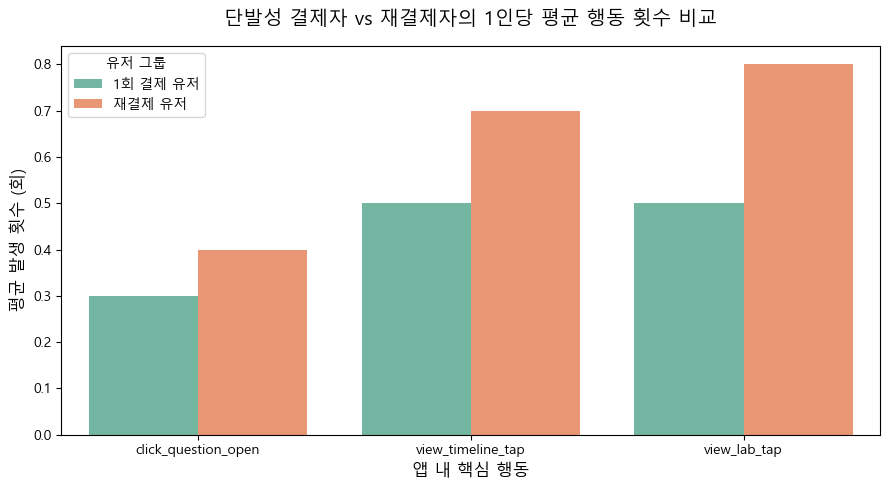

In [12]:
print("========== [재결제 관련 심층 행동 분석] ==========")

try:
    # ==========================================
    # 1. 데이터 준비 및 전처리
    # ==========================================
    df_pay = paymenthistory_clean.copy()
    df_evt = hackle_events.copy()

    # ID 및 시간 타입 통일
    df_pay['user_id'] = df_pay['user_id'].astype(str)
    df_evt['session_id'] = df_evt['session_id'].astype(str)

    if 'user_id' not in df_evt.columns:
        h_prop = hackle_prop.drop_duplicates(subset=['session_id']).copy()
        h_prop['session_id'] = h_prop['session_id'].astype(str)
        df_evt = pd.merge(df_evt, h_prop[['session_id', 'user_id']], on='session_id', how='left')

    df_evt['user_id'] = df_evt['user_id'].astype(str)
    df_pay['created_at'] = pd.to_datetime(df_pay['created_at'], errors='coerce')
    df_evt['event_datetime'] = pd.to_datetime(df_evt['event_datetime'], errors='coerce')

    # 결제 시간순 정렬
    df_pay = df_pay.dropna(subset=['created_at']).sort_values(by=['user_id', 'created_at'])

    # ==========================================
    # 2. 1차, 2차 결제 시간 추출 및 그룹 분리
    # ==========================================
    df_pay['pay_order'] = df_pay.groupby('user_id').cumcount() + 1

    pay_1st = df_pay[df_pay['pay_order'] == 1][['user_id', 'created_at']].rename(columns={'created_at': 'time_1st'})
    pay_2nd = df_pay[df_pay['pay_order'] == 2][['user_id', 'created_at']].rename(columns={'created_at': 'time_2nd'})

    user_pay_stats = pd.merge(pay_1st, pay_2nd, on='user_id', how='left')

    # 그룹 정의: 2차 결제 시간이 있으면 '재결제 유저', 없으면 '1회 결제 유저'
    user_pay_stats['user_group'] = np.where(user_pay_stats['time_2nd'].notna(), '재결제 유저', '1회 결제 유저')

    # ==========================================
    # [분석 1] 재결제 소요 시간(Time-to-Repurchase) 분포
    # ==========================================
    print("\n▶ 1. 첫 결제 후 두 번째 결제까지 걸린 시간 분석")
    repurchasers = user_pay_stats[user_pay_stats['user_group'] == '재결제 유저'].copy()
    repurchasers['days_to_repurchase'] = (repurchasers['time_2nd'] - repurchasers['time_1st']).dt.days

    # 구간(Bin) 설정
    bins = [-1, 0, 1, 3, 7, 14, 30, 9999]
    labels = ['당일 재결제(0일)', '1일 후', '2~3일 후', '4~7일 후', '8~14일 후', '15~30일 후', '31일 이상']
    repurchasers['repurchase_timing'] = pd.cut(repurchasers['days_to_repurchase'], bins=bins, labels=labels)

    # 통계 집계
    timing_stats = repurchasers['repurchase_timing'].value_counts().reset_index()
    timing_stats.columns = ['재결제 소요 기간', '유저 수']

    # 정렬 유지
    timing_stats['재결제 소요 기간'] = pd.Categorical(timing_stats['재결제 소요 기간'], categories=labels, ordered=True)
    timing_stats = timing_stats.sort_values('재결제 소요 기간')

    timing_stats['비율(%)'] = (timing_stats['유저 수'] / len(repurchasers) * 100).round(1)

    display(timing_stats.style.bar(subset=['비율(%)'], color='#ffb3b3', vmin=0, vmax=100))

    # ==========================================
    # [분석 2] 그룹별 핵심 행동(질문 열기 등) 활성도 비교
    # ==========================================
    print("\n▶ 2. 1회 결제 유저 vs 재결제 유저의 핵심 행동 활성도 비교")

    # 앱 내 가치를 가장 잘 보여주는 핵심 이벤트 3가지
    core_events = ['click_question_open', 'view_timeline_tap', 'view_lab_tap']
    evt_filtered = df_evt[df_evt['event_key'].isin(core_events)]

    # 유저별 이벤트 발생 횟수 집계
    user_event_counts = evt_filtered.groupby(['user_id', 'event_key']).size().unstack(fill_value=0).reset_index()

    # 결제 그룹 정보 병합
    compare_df = pd.merge(user_pay_stats[['user_id', 'user_group']], user_event_counts, on='user_id', how='left').fillna(0)

    # 그룹별 유저 1인당 평균 행동 횟수 계산
    avg_behavior = compare_df.groupby('user_group')[core_events].mean().round(1).T
    avg_behavior.columns.name = None
    avg_behavior.index.name = '핵심 행동 (event_key)'

    # 차이 배수 계산
    avg_behavior['차이(배)'] = (avg_behavior['재결제 유저'] / avg_behavior['1회 결제 유저']).replace([np.inf, 0], 1).round(1)

    display(avg_behavior)

    # ==========================================
    # 3. 그룹별 행동 볼륨 비교 시각화
    # ==========================================
    avg_behavior_melted = avg_behavior[['1회 결제 유저', '재결제 유저']].reset_index().melt(
        id_vars='핵심 행동 (event_key)', var_name='유저 그룹', value_name='평균 발생 횟수'
    )

    plt.figure(figsize=(9, 5))
    sns.barplot(data=avg_behavior_melted, x='핵심 행동 (event_key)', y='평균 발생 횟수', hue='유저 그룹', palette='Set2')

    plt.title('단발성 결제자 vs 재결제자의 1인당 평균 행동 횟수 비교', fontsize=14, pad=15)
    plt.xlabel('앱 내 핵심 행동', fontsize=12)
    plt.ylabel('평균 발생 횟수 (회)', fontsize=12)
    plt.legend(title='유저 그룹')
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"에러: {e}")

### 2-5. 결제 후 7일 내 행동 횟수별 재결제율

,결제 후 7일 내 click_question_open 횟수,해당 유저 수(명),재결제율(%)
0,0회,58819,27.300000
1,1회,157,25.500000
2,2회,72,25.000000
3,3회,28,25.000000
4,4~5회,36,27.800000
5,6~10회,38,36.800000
6,11회 이상,42,26.200000


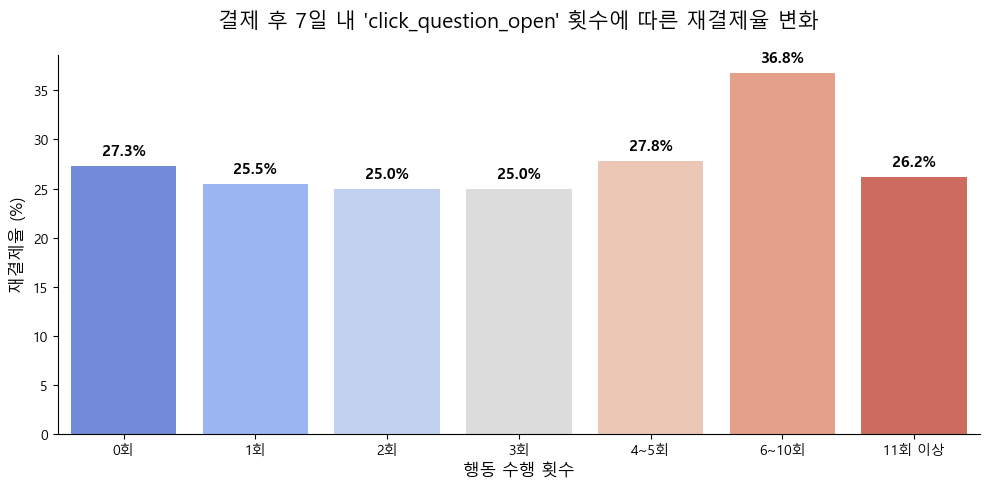

In [13]:
try:
    # ==========================================
    # 0. 데이터 전처리
    # ==========================================
    df_pay = paymenthistory_clean.copy()
    df_evt = hackle_events.copy()

    df_pay['user_id'] = df_pay['user_id'].astype(str)
    df_evt['session_id'] = df_evt['session_id'].astype(str)

    if 'user_id' not in df_evt.columns:
        h_prop = hackle_prop.drop_duplicates(subset=['session_id']).copy()
        h_prop['session_id'] = h_prop['session_id'].astype(str)
        df_evt = pd.merge(df_evt, h_prop[['session_id', 'user_id']], on='session_id', how='left')

    df_evt['user_id'] = df_evt['user_id'].astype(str)
    df_pay['created_at'] = pd.to_datetime(df_pay['created_at'], errors='coerce')
    df_evt['event_datetime'] = pd.to_datetime(df_evt['event_datetime'], errors='coerce')

    # ==========================================
    # 1. 유저별 1차 및 2차 결제 시점 추출
    # ==========================================
    df_pay = df_pay.dropna(subset=['created_at']).sort_values(by=['user_id', 'created_at'])
    df_pay['pay_order'] = df_pay.groupby('user_id').cumcount() + 1

    pay_1st = df_pay[df_pay['pay_order'] == 1][['user_id', 'created_at']].rename(columns={'created_at': 'time_1st'})
    pay_2nd = df_pay[df_pay['pay_order'] == 2][['user_id', 'created_at']].rename(columns={'created_at': 'time_2nd'})

    users_df = pd.merge(pay_1st, pay_2nd, on='user_id', how='left')
    users_df['is_repurchased'] = users_df['time_2nd'].notna().astype(int) # 재결제 여부 (0 또는 1)

    # ==========================================
    # 2. 첫 결제 후 7일 내 '질문 열기' 횟수 카운트
    # ==========================================
    # 분석할 핵심 행동
    target_event = 'click_question_open'

    evt_target = df_evt[df_evt['event_key'] == target_event].copy()
    evt_target = pd.merge(evt_target, users_df[['user_id', 'time_1st']], on='user_id', how='inner')

    # 1차 결제 이후 7일 이내 행동만 사용
    evt_target['days_since_1st'] = (evt_target['event_datetime'] - evt_target['time_1st']).dt.total_seconds() / 86400
    valid_evts = evt_target[(evt_target['days_since_1st'] >= 0) & (evt_target['days_since_1st'] <= 7)]

    # 유저별 횟수 집계
    user_evt_counts = valid_evts.groupby('user_id').size().reset_index(name='action_count')
    users_df = pd.merge(users_df, user_evt_counts, on='user_id', how='left')
    users_df['action_count'] = users_df['action_count'].fillna(0)

    # ==========================================
    # 3. 행동 횟수별 재결제율(Conversion Rate) 계산
    # ==========================================
    # 행동 횟수 구간(Bin) 설정
    bins = [-1, 0, 1, 2, 3, 5, 10, 9999]
    labels = ['0회', '1회', '2회', '3회', '4~5회', '6~10회', '11회 이상']
    users_df['action_bin'] = pd.cut(users_df['action_count'], bins=bins, labels=labels)

    aha_stats = users_df.groupby('action_bin', observed=False).agg(
        total_users=('user_id', 'count'),
        repurchasers=('is_repurchased', 'sum')
    ).reset_index()

    aha_stats['재결제율(%)'] = (aha_stats['repurchasers'] / aha_stats['total_users'] * 100).round(1)

    display_df = aha_stats[['action_bin', 'total_users', '재결제율(%)']].rename(
        columns={'action_bin': f'결제 후 7일 내 {target_event} 횟수', 'total_users': '해당 유저 수(명)'}
    )
    display(display_df.style.background_gradient(cmap='YlGn', subset=['재결제율(%)']))

    # ==========================================
    # 4. 시각화
    # ==========================================
    plt.figure(figsize=(10, 5))

    # 막대 그래프 그리기 (재결제율)
    ax = sns.barplot(
        data=aha_stats,
        x='action_bin',
        y='재결제율(%)',
        hue='action_bin',
        palette='coolwarm',
        legend=False
    )

    # 수치 표시
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%",
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, fontweight='bold', color='black', xytext=(0, 5), textcoords='offset points')

    plt.title(f"결제 후 7일 내 '{target_event}' 횟수에 따른 재결제율 변화", fontsize=15, pad=20)
    plt.xlabel('행동 수행 횟수', fontsize=12)
    plt.ylabel('재결제율 (%)', fontsize=12)

    sns.despine()
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"에러: {e}")

### 2-6. 요일·시간대별 결제 분포

========== [요일 및 시간대별 결제 집중도 분석] ==========


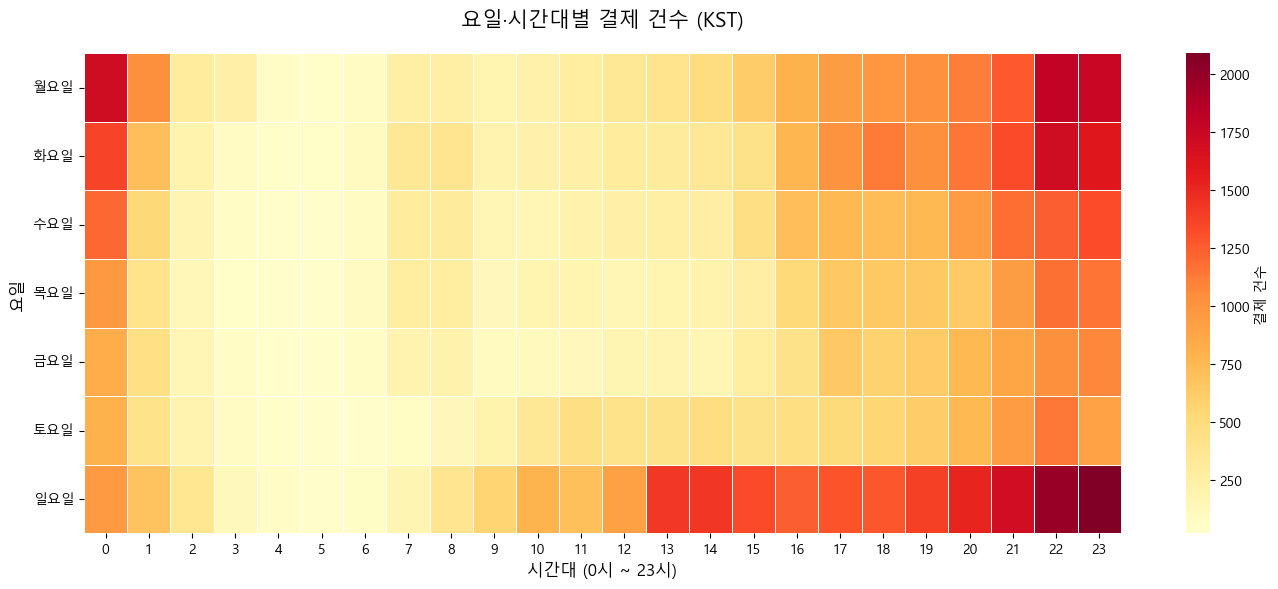


[결제가 가장 많은 요일·시간대 Top 5]


요일,시간대,결제 건수
일요일,23시,2090
일요일,22시,1979
월요일,22시,1791
월요일,23시,1763
월요일,0시,1716


In [14]:
print("========== [요일 및 시간대별 결제 집중도 분석] ==========")

try:
    # ==========================================
    # 1. 데이터 준비 및 전처리
    # ==========================================
    df_pay = paymenthistory_clean.copy()

    # 시간 데이터 변환 및 결측치 제거
    df_pay['created_at'] = pd.to_datetime(df_pay['created_at'], errors='coerce')
    df_pay = df_pay.dropna(subset=['created_at'])

    # ==========================================
    # 2. 시간(Hour) 및 요일(Weekday) 추출
    # ==========================================
    # 0~23시 추출
    df_pay['hour'] = df_pay['created_at'].dt.hour

    # 요일 추출 (0=월요일, 6=일요일)
    weekday_map = {0: '월요일', 1: '화요일', 2: '수요일', 3: '목요일', 4: '금요일', 5: '토요일', 6: '일요일'}
    df_pay['weekday'] = df_pay['created_at'].dt.dayofweek.map(weekday_map)

    # 월~일 순서 지정
    weekday_order = ['월요일', '화요일', '수요일', '목요일', '금요일', '토요일', '일요일']
    df_pay['weekday'] = pd.Categorical(df_pay['weekday'], categories=weekday_order, ordered=True)

    # ==========================================
    # 3. 요일-시간대 교차표(Crosstab) 생성
    # ==========================================
    heatmap_data = pd.crosstab(df_pay['weekday'], df_pay['hour'])

    # ==========================================
    # 4. 히트맵 시각화
    # ==========================================
    plt.figure(figsize=(14, 6))

    sns.heatmap(
        heatmap_data,
        cmap='YlOrRd',
        annot=False,
        linewidths=.5,
        cbar_kws={'label': '결제 건수'}
    )

    plt.title('요일·시간대별 결제 건수 (KST)', fontsize=15, pad=20)
    plt.xlabel('시간대 (0시 ~ 23시)', fontsize=12)
    plt.ylabel('요일', fontsize=12)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # ==========================================
    # 5. 결제가 가장 많은 시간대 Top 5
    # ==========================================
    flat_data = heatmap_data.stack().reset_index()
    flat_data.columns = ['요일', '시간대', '결제 건수']
    hot_times = flat_data.sort_values(by='결제 건수', ascending=False).head(5).copy()

    print("\n[결제가 가장 많은 요일·시간대 Top 5]")
    hot_times['시간대'] = hot_times['시간대'].astype(str) + "시"
    display(hot_times.style.hide(axis='index').background_gradient(cmap='Reds', subset=['결제 건수']))

except Exception as e:
    print(f"에러: {e}")

### 2-7. 월별 코호트 재결제율

> 상품별 가격은 원본에 없어 가정값을 사용했습니다. 금액 지표(ARPPU)는 참고용입니다.

In [15]:
# KST 기준 결제 내역 사용
df_payments = paymenthistory_clean.copy()
df_payments['created_at'] = pd.to_datetime(df_payments['created_at'], errors='coerce')
df_payments = df_payments.dropna(subset=['created_at'])

# ==========================================
# 1. ARPPU (유저 1인당 평균 결제 금액) 분석
# ==========================================
print("========== [1. 유저 1인당 평균 결제 금액(ARPPU) 분석] ==========")

# 상품별 가격(원): 원본에 가격 정보가 없어 가정값 사용
price_mapping = {
    'heart.777': 7700,
    'heart.1000': 10000,
    'heart.200': 2000,
    'heart.4000': 40000
}

df_payments['price'] = df_payments['productId'].map(price_mapping)

# 유저별 총 결제 금액 계산
user_total_spend = df_payments.groupby('user_id')['price'].sum()

# ARPPU 계산 (전체 결제 금액 / 결제 유저 수)
total_revenue = user_total_spend.sum()
paying_user_count = len(user_total_spend)
arppu = total_revenue / paying_user_count if paying_user_count > 0 else 0

print(f"▶ 누적 추정 결제액: {total_revenue:,.0f}원")
print(f"▶ 결제 유저 수: {paying_user_count:,}명")
print(f"▶ 유저 1인당 평균 결제 금액(ARPPU): {arppu:,.0f}원\n")

# ==========================================
# 2. 월별 재결제율(Cohort Retention) 분석
# ==========================================
print("========== [2. 월별 코호트 재결제율 분석] ==========")

# 1) 결제 발생 '월(Month)' 정보 추출
df_payments['order_month'] = df_payments['created_at'].dt.to_period('M')

# 2) 유저별 '최초 결제월' 구하기
first_purchase = df_payments.groupby('user_id')['order_month'].min().reset_index()
first_purchase.columns = ['user_id', 'first_month']

# 3) 원본 결제 기록에 최초 결제월 정보 합치기
df_merged = pd.merge(df_payments, first_purchase, on='user_id')

# 4) 최초 결제월로부터 몇 개월(Month Diff)이 지났는지 계산
df_merged['month_diff'] = (df_merged['order_month'] - df_merged['first_month']).apply(lambda x: x.n)

# 5) 코호트 테이블 생성 (최초 결제월 기준, N개월 후 결제한 유저 수)
cohort_data = df_merged.groupby(['first_month', 'month_diff'])['user_id'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='first_month', columns='month_diff', values='user_id')

# 6) 유저 수를 비율(%)로 변환
cohort_sizes = cohort_pivot.iloc[:, 0] # month_diff 0 (당월 결제 유저 수)
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0) * 100

retention_matrix_styled = retention_matrix.style.format("{:.1f}%", na_rep="-").background_gradient(cmap='YlGn', axis=None, vmin=0, vmax=20).highlight_null(color='white')

display(retention_matrix_styled)

========== [1. 유저 1인당 평균 결제 금액(ARPPU) 분석] ==========
▶ 누적 추정 결제액: 755,796,100원
▶ 결제 유저 수: 59,192명
▶ 유저 1인당 평균 결제 금액(ARPPU): 12,769원

========== [2. 월별 코호트 재결제율 분석] ==========


month_diff,0,1,2,3,4,5,6,7,8,9,10,11,12
first_month,,,,,,,,,,,,,
2023-05,100.0%,3.1%,0.8%,0.6%,0.2%,0.0%,0.1%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
2023-06,100.0%,1.4%,1.3%,0.3%,0.1%,0.0%,0.1%,0.1%,-,-,0.0%,-,-
2023-07,100.0%,0.9%,0.4%,0.2%,-,0.1%,0.1%,0.1%,-,-,-,-,-
2023-08,100.0%,0.7%,0.3%,0.1%,0.1%,-,-,-,-,-,-,-,-
2023-09,100.0%,0.4%,-,0.4%,-,0.4%,-,-,-,-,-,-,-
2023-10,100.0%,-,-,-,-,-,-,-,-,-,-,-,-
2023-11,100.0%,1.1%,-,-,-,-,-,-,-,-,-,-,-
2023-12,100.0%,-,1.4%,-,-,-,-,-,-,-,-,-,-
2024-01,100.0%,-,-,-,-,-,-,-,-,-,-,-,-


## 3. 정리

- 전체 가입자 677,081명 중 결제 유저는 59,192명(8.74%)이었고, 가장 많이 팔린 상품은 777하트(57,873건)였습니다.
- 첫 결제의 74.2%가 가입 후 7일 안에 발생했습니다.
- 재결제 유저의 63.8%는 첫 결제 당일에 다시 결제했습니다. 첫 결제 직후가 재결제를 유도할 시점입니다.
- 결제는 일요일·월요일 밤 22시~0시(KST)에 가장 많았습니다.
- 결제 후 7일 내 질문 열기 횟수별 재결제율은 구간별 유저 수가 수십 명 수준이라 차이를 결론으로 쓰지 않았습니다. Hackle 로그와 연결되는 결제 유저가 적었기 때문입니다.
- 이를 바탕으로 777하트 첫 구매 추천 배지, 결과 화면 충전소 버튼 등 A/B 테스트를 제안했습니다.
